In [56]:
import Pkg

Pkg.activate(dirname(@__DIR__))
Pkg.add(["DynamicalSystems", "CairoMakie", "OrdinaryDiffEq", "BenchmarkTools"])
Pkg.status(["DynamicalSystems", "CairoMakie", "OrdinaryDiffEq", "BenchmarkTools"]; mode = Pkg.PKGMODE_MANIFEST)
Pkg.instantiate()
Base.active_project()

  Activating project at `~/Documents/Git`
     Project 

Status `~/Documents/Git/Manifest.toml`
  

No packages added to or removed from `~/Documents/Git/Project.toml`
    Manifest No packages added to or removed from `~/Documents/Git/Manifest.toml`


[47edcb42] ADTypes v1.24.0
  [f3fd9213] Attractors v2.0.5
  [6e4b80f9] BenchmarkTools v1.8.0
  [159f3aea] Cairo v1.1.1
⌃ [13f3f980] CairoMakie v0.15.15
  [608a59af] ChaosTools v3.5.4
⌃ [5ae59095] Colors v0.13.2
  [38540f10] CommonSolve v0.2.14
  [34da2185] Compat v4.18.1
  [ab4b797d] ComplexityMeasures v3.11.0
  [864edb3b] DataStructures v0.19.6
  [5732040d] DelayEmbeddings v2.9.0
⌃ [2b5f629d] DiffEqBase v7.21.3
⌅ [ffbed154] DocStringExtensions v0.9.5
  [61744808] DynamicalSystems v3.7.0
  [6e36e845] DynamicalSystemsBase v3.19.3
  [5789e2e9] FileIO v1.20.0
  [4665ce21] FractalDimensions v1.9.6
  [b38be410] FreeType v4.1.1
  [5c1252a2] GeometryBasics v0.5.13
  [682c06a0] JSON v1.10.0
⌅ [ee78f7c6] Makie v0.24.15
  [1dea7af3] OrdinaryDiffEq v7.8.1
⌃ [6ad6398a] OrdinaryDiffEqBDF v2.4.12
⌃ [bbf590c4] OrdinaryDiffEqCore v4.18.1
  [50262376] OrdinaryDiffEqDefault v2.6.2
  [43230ef6] OrdinaryDiffEqRosenbrock v2.7.5
  [b1df2697] OrdinaryDiffEqTsit5 v2.1.5
  [79d7bb75] OrdinaryDiffEqVerner v2.4.

"/home/stan/Documents/Git/Project.toml"

In [57]:
using DynamicalSystems
using CairoMakie
using Statistics

## Question 1

### 1.3

In [58]:
function q1(u, p, t)
    x, y, z = u
    a, b, c = p
    dx = - y - z
    dy = x + a*y
    dz = b + z*(x-c)
    return SVector(dx, dy, dz)
end

q1 (generic function with 1 method)

In [83]:
display("text/markdown", Base.doc(scatter))

```julia
scatter(positions)
scatter(x, y)
scatter(x, y, z)
```

Plots a marker for each element in `(x, y, z)`, `(x, y)`, or `positions`.

## Plot type

The plot type alias for the `scatter` function is `Scatter`.

## Attributes

**`alpha`** =  `1.0`  — The alpha value of the colormap or color attribute. Multiple alphas like in `plot(alpha=0.2, color=(:red, 0.5))`, will get multiplied.

**`clip_planes`** =  `@inherit clip_planes automatic`  — Clip planes offer a way to do clipping in 3D space. You can set a Vector of up to 8 `Plane3f` planes here, behind which plots will be clipped (i.e. become invisible). By default clip planes are inherited from the parent plot or scene. You can remove parent `clip_planes` by passing `Plane3f[]`.

**`color`** =  `@inherit markercolor`  — Sets the color of the marker. If no color is set, multiple calls to `scatter!` will cycle through the axis color palette.

**`colormap`** =  `@inherit colormap :viridis`  — Sets the colormap that is sampled for numeric `color`s. `PlotUtils.cgrad(...)`, `Makie.Reverse(any_colormap)` can be used as well, or any symbol from ColorBrewer or PlotUtils. To see all available color gradients, you can call `Makie.available_gradients()`.

**`colorrange`** =  `automatic`  — The values representing the start and end points of `colormap`.

**`colorscale`** =  `identity`  — The color transform function. Can be any function, but only works well together with `Colorbar` for `identity`, `log`, `log2`, `log10`, `sqrt`, `logit`, `Makie.pseudolog10`, `Makie.Symlog10`, `Makie.AsinhScale`, `Makie.SinhScale`, `Makie.LogScale`, `Makie.LuptonAsinhScale`, and `Makie.PowerScale`.

**`cycle`** =  `[:color]`  — Sets which attributes to cycle when creating multiple plots. The values to cycle through are defined by the parent Theme. Multiple cycled attributes can be set by passing a vector. Elements can

  * directly refer to a cycled attribute, e.g. `:color`
  * map a cycled attribute to a palette attribute, e.g. `:linecolor => :color`
  * map multiple cycled attributes to a palette attribute, e.g. `[:linecolor, :markercolor] => :color`

**`depth_shift`** =  `0.0`  — Adjusts the depth value of a plot after all other transformations, i.e. in clip space, where `-1 <= depth <= 1`. This only applies to GLMakie and WGLMakie and can be used to adjust render order (like a tunable overdraw).

**`depthsorting`** =  `false`  — Enables depth-sorting of markers which can improve border artifacts. Currently supported in GLMakie only.

**`distancefield`** =  `nothing`  — Optional distancefield used for e.g. font and bezier path rendering. Will get set automatically.

**`font`** =  `"default"`  — Sets the font to be used for character markers

**`fxaa`** =  `false`  — Adjusts whether the plot is rendered with fxaa (fast approximate anti-aliasing, GLMakie only). Note that some plots implement a better native anti-aliasing solution (scatter, text, lines). For them `fxaa = true` generally lowers quality. Plots that show smoothly interpolated data (e.g. image, surface) may also degrade in quality as `fxaa = true` can cause blurring.

**`glowcolor`** =  `(:black, 0.0)`  — Sets the color of the glow effect around the marker.

**`glowwidth`** =  `0.0`  — Sets the size of a glow effect around the marker.

**`highclip`** =  `automatic`  — The color for any value above the colorrange.

**`inspectable`** =  `@inherit inspectable`  — Sets whether this plot should be seen by `DataInspector`. The default depends on the theme of the parent scene.

**`inspector_clear`** =  `automatic`  — Sets a callback function `(inspector, plot) -> ...` for cleaning up custom indicators in DataInspector.

**`inspector_hover`** =  `automatic`  — Sets a callback function `(inspector, plot, index) -> ...` which replaces the default `show_data` methods.

**`inspector_label`** =  `automatic`  — Sets a callback function `(plot, index, position) -> string` which replaces the default label generated by DataInspector.

**`lowclip`** =  `automatic`  — The color for any value below the colorrange.

**`marker`** =  `@inherit marker`  — Sets the scatter marker.

**`marker_offset`** =  `Vec3f(0)`  — The offset of the marker from the given position in `markerspace` units. An offset of 0 corresponds to a centered marker.

**`markersize`** =  `@inherit markersize`  — Sets the size of the marker by scaling it relative to its base size which can differ for each marker. A `Real` scales x and y dimensions by the same amount. A `Vec` or `Tuple` with two elements scales x and y separately. An array of either scales each marker separately. Humans perceive the area of a marker as its size which grows quadratically with `markersize`, so multiplying `markersize` by 2 results in a marker that is 4 times as large, visually.

**`markerspace`** =  `:pixel`  — Sets the space in which `markersize` is given. See `Makie.spaces()` for possible inputs

**`model`** =  `automatic`  — Sets a model matrix for the plot. This overrides adjustments made with `translate!`, `rotate!` and `scale!`.

**`nan_color`** =  `:transparent`  — The color for NaN values.

**`overdraw`** =  `false`  — Controls if the plot will draw over other plots. This specifically means ignoring depth checks in GL backends

**`rasterize`** =  `@inherit rasterize false`  — Controls whether CairoMakie rasterizes a plot (true, >0) or not (false, 0). If an integer is given, it sets the pixel density for rasterization.

**`rotation`** =  `Billboard()`  — Sets the rotation of the marker. A `Billboard` rotation is always around the depth axis.

**`space`** =  `:data`  — Sets the transformation space for box encompassing the plot. See `Makie.spaces()` for possible inputs.

**`ssao`** =  `false`  — Adjusts whether the plot is rendered with ssao (screen space ambient occlusion). Note that this only makes sense in 3D plots and is only applicable with `fxaa = true`.

**`strokecolor`** =  `@inherit markerstrokecolor`  — Sets the color of the outline around a marker.

**`strokewidth`** =  `@inherit markerstrokewidth`  — Sets the width of the outline around a marker.

**`transform_marker`** =  `false`  — Controls whether the model matrix (without translation) applies to the marker itself, rather than just the positions. (If this is true, `scale!` and `rotate!` will affect the marker.

**`transformation`** =  `:automatic`  — Controls the inheritance or directly sets the transformations of a plot. Transformations include the transform function and model matrix as generated by `translate!(...)`, `scale!(...)` and `rotate!(...)`. They can be set directly by passing a `Transformation()` object or inherited from the parent plot or scene. Inheritance options include:

  * `:automatic`: Inherit transformations if the parent and child `space` is compatible
  * `:inherit`: Inherit transformations
  * `:inherit_model`: Inherit only model transformations
  * `:inherit_transform_func`: Inherit only the transform function
  * `:nothing`: Inherit neither, fully disconnecting the child's transformations from the parent

Another option is to pass arguments to the `transform!()` function which then get applied to the plot. For example `transformation = (:xz, 1.0)` which rotates the `xy` plane to the `xz` plane and translates by `1.0`. For this inheritance defaults to `:automatic` but can also be set through e.g. `(:nothing, (:xz, 1.0))`.

**`transparency`** =  `false`  — Adjusts how the plot deals with transparency. In GLMakie `transparency = true` results in using Order Independent Transparency.

**`visible`** =  `true`  — Controls whether the plot gets rendered or not.


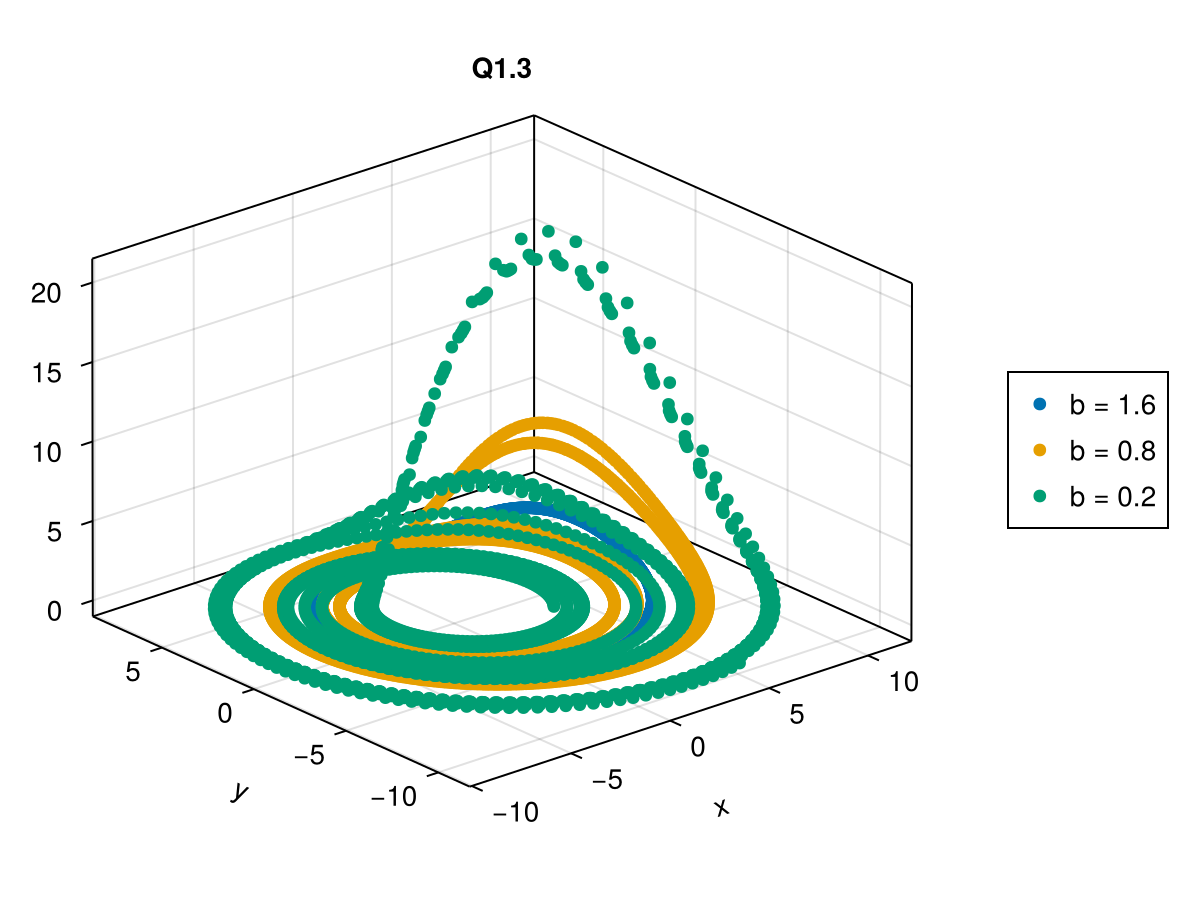

CairoMakie.Screen{IMAGE}


In [60]:
b_vals = [1.6, 0.8, 0.2]
colours = ["red", "green", "blue"]
graphs = []

fig = Figure()
ax = Axis3(fig[1, 1]; title = "Q1.3")

for b in b_vals
    p0 = [0.2, b, 5.7]
    u0 = [5.2, 0, 0]
    q1vals = CoupledODEs(q1, u0, p0)
    total_time = 100
    X, t = trajectory(q1vals, total_time; Ttr = 1000, Δt = 0.05)
    graph = scatter!(ax, X)
    push!(graphs, graph)
end

Legend(fig[1, 2], graphs, ["b = 1.6", "b = 0.8", "b = 0.2"])
display(fig)

### 1.4

In [61]:
mean_x_vals = []
mean_z_vals = []
b_values = []
for b in 0.2:0.01:1.6
    p0 = [0.2, b, 5.7]
    u0 = [5.2, 0, 0]
    q1_4vals = CoupledODEs(q1, u0, p0)
    total_time = 1_000
    X, t = trajectory(q1_4vals, total_time; Ttr = 0000)
    x_vals, _, z_vals = columns(X)
    mean_x = mean(x_vals)
    mean_z = mean(z_vals)
    push!(mean_x_vals, mean_x)
    push!(mean_z_vals, mean_z)
    push!(b_values, b)
end



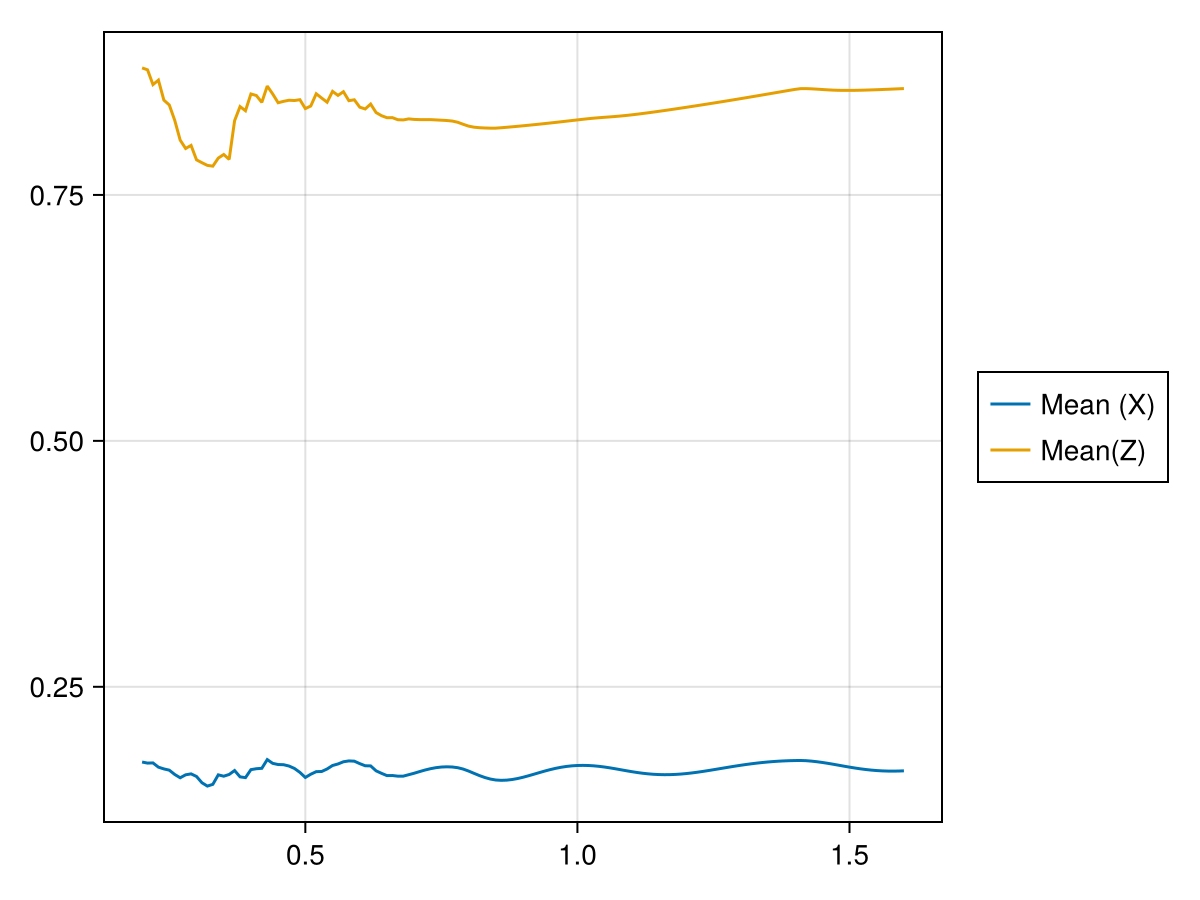

In [62]:
fig = Figure()
ax = Axis(fig[1,1])
x_graph = lines!(ax, b_values, mean_x_vals)
z_graph = lines!(ax, b_values, mean_z_vals)
Legend(fig[1, 2], [x_graph, z_graph], ["Mean (X)", "Mean(Z)"])
fig

In [82]:
display("text/markdown", Base.doc(poincaresos))

```julia
poincaresos(A::AbstractStateSpaceSet, plane; kwargs...) → P::StateSpaceSet
```

Calculate the Poincaré surface of section of the given dataset with the given `plane` by performing linear interpolation betweeen points that sandwich the hyperplane.

Argument `plane` and keywords `direction, warning, save_idxs` are the same as in [`PoincareMap`](@ref).

```julia
poincaresos(ds::CoupledODEs, plane, T = 1000.0; kwargs...) → P::StateSpaceSet
```

Return the iterations of `ds` on the Poincaré surface of section with the `plane`, by evolving `ds` up to a total of `T`. Return a [`StateSpaceSet`](@ref) of the points that are on the surface of section.

This function initializes a [`PoincareMap`](@ref) and steps it until its [`current_crossing_time`](@ref) exceeds `T`. You can also use [`trajectory`](@ref) with [`PoincareMap`](@ref) to get a sequence of `N::Int` points instead.

The keywords `Ttr, save_idxs` act as in [`trajectory`](@ref). See [`PoincareMap`](@ref) for `plane` and all other keywords.


In [87]:
display("text/markdown", Base.doc(PoincareMap))

```julia
PoincareMap <: DiscreteTimeDynamicalSystem
PoincareMap(ds::CoupledODEs, plane; kwargs...) → pmap
```

A discrete time dynamical system that produces iterations over the Poincaré map[^DatserisParlitz2022] of the given continuous time `ds`. This map is defined as the sequence of points on the Poincaré surface of section, which is defined by the `plane` argument.

Iterating `pmap` also mutates `ds` which is referenced in `pmap`.

See also [`StroboscopicMap`](@ref), [`poincaresos`](@ref).

## Keyword arguments

  * `direction = -1`: Only crossings with `sign(direction)` are considered to belong to the surface of section. Negative direction means going from less than $b$ to greater than $b$.
  * `u0 = nothing`: Specify an initial state. If `nothing` it is the `current_state(ds)`.
  * `rootkw = (xrtol = 1e-6, atol = 1e-8)`: A `NamedTuple` of keyword arguments passed to `find_zero` from [Roots.jl](https://github.com/JuliaMath/Roots.jl).
  * `Tmax = 1e3`: The argument `Tmax` exists so that the integrator can terminate instead of being evolved for infinite time, to avoid cases where iteration would continue forever for ill-defined hyperplanes or for convergence to fixed points, where the trajectory would never cross again the hyperplane. If during one `step!` the system has been evolved for more than `Tmax`, then `step!(pmap)` will terminate and error.

## Description

The Poincaré surface of section is defined as sequential transversal crossings a trajectory has with any arbitrary manifold, but here the manifold must be a hyperplane. `PoincareMap` iterates over the crossings of the section.

If the state of `ds` is $\mathbf{u} = (u_1, \ldots, u_D)$ then the equation defining a hyperplane is

$$
a_1u_1 + \dots + a_Du_D = \mathbf{a}\cdot\mathbf{u}=b
$$

where $\mathbf{a}, b$ are the parameters of the hyperplane.

In code, `plane` can be either:

  * A `Tuple{Int, <: Real}`, like `(j, r)`: the plane is defined as when the `j`th variable of the system equals the value `r`.
  * A vector of length `D+1`. The first `D` elements of the vector correspond to $\mathbf{a}$ while the last element is $b$.

`PoincareMap` uses `ds`, higher order interpolation from DifferentialEquations.jl, and root finding from Roots.jl, to create a high accuracy estimate of the section.

`PoincareMap` follows the [`DynamicalSystem`](@ref) interface with the following adjustments:

1. `dimension(pmap) == dimension(ds)`, even though the Poincaré map is effectively 1 dimension less.
2. Like [`StroboscopicMap`](@ref) time is discrete and counts the iterations on the surface of section. [`initial_time`](@ref) is always `0` and [`current_time`](@ref) is current iteration number.
3. A new function [`current_crossing_time`](@ref) returns the real time corresponding to the latest crossing of the hyperplane. The corresponding state on the hyperplane is `current_state(pmap)` as expected.
4. For the special case of `plane` being a `Tuple{Int, <:Real}`, a special `reinit!` method is allowed with input state of length `D-1` instead of `D`, i.e., a reduced state already on the hyperplane that is then converted into the `D` dimensional state.
5. The `initial_state(pmap)` returns the state initial state of the map. This is not `u0` because `u0` is evolved forwards until it resides on the Poincaré plane.
6. In the `reinit!` function, the `t0` keyword denotes the starting time of the continuous time dynamical system, as the starting time of the `PoincareMap` is by definition always 0.

## Example

```julia
using DynamicalSystemsBase, PredefinedDynamicalSystems
ds = Systems.rikitake(zeros(3); μ = 0.47, α = 1.0)
pmap = poincaremap(ds, (3, 0.0))
step!(pmap)
next_state_on_psos = current_state(pmap)
```

[^DatserisParlitz2022]: Datseris & Parlitz 2022, *Nonlinear Dynamics: A Concise Introduction Interlaced with Code*, [Springer Nature, Undergrad. Lect. Notes In Physics](https://doi.org/10.1007/978-3-030-91032-7)


In [89]:
display("text/markdown", Base.doc(current_crossing_time))

```julia
current_crossing_time(pmap::PoincareMap) → tcross
```

Return the time of the latest crossing of the Poincare section.


In [64]:
set_parameter!(q1_4vals, 2, 0.2) # Set 2nd param (b) to 0.2
current_parameters(q1_4vals)
u0 = [5.2, 0, 0]

UndefVarError: UndefVarError: `q1_4vals` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [ ]:
function psos1(A, index, value)
    # Estimate poincare section of traj(A) with hyperplane defined for when var(traj) with given index
    # crosses a specific value (- => +)
    # Use interpolation
    plane = (index, value)
    pmap = poincaresos(A, plane, 1000, direction = -1)
    return pmap
end

psos1 (generic function with 1 method)

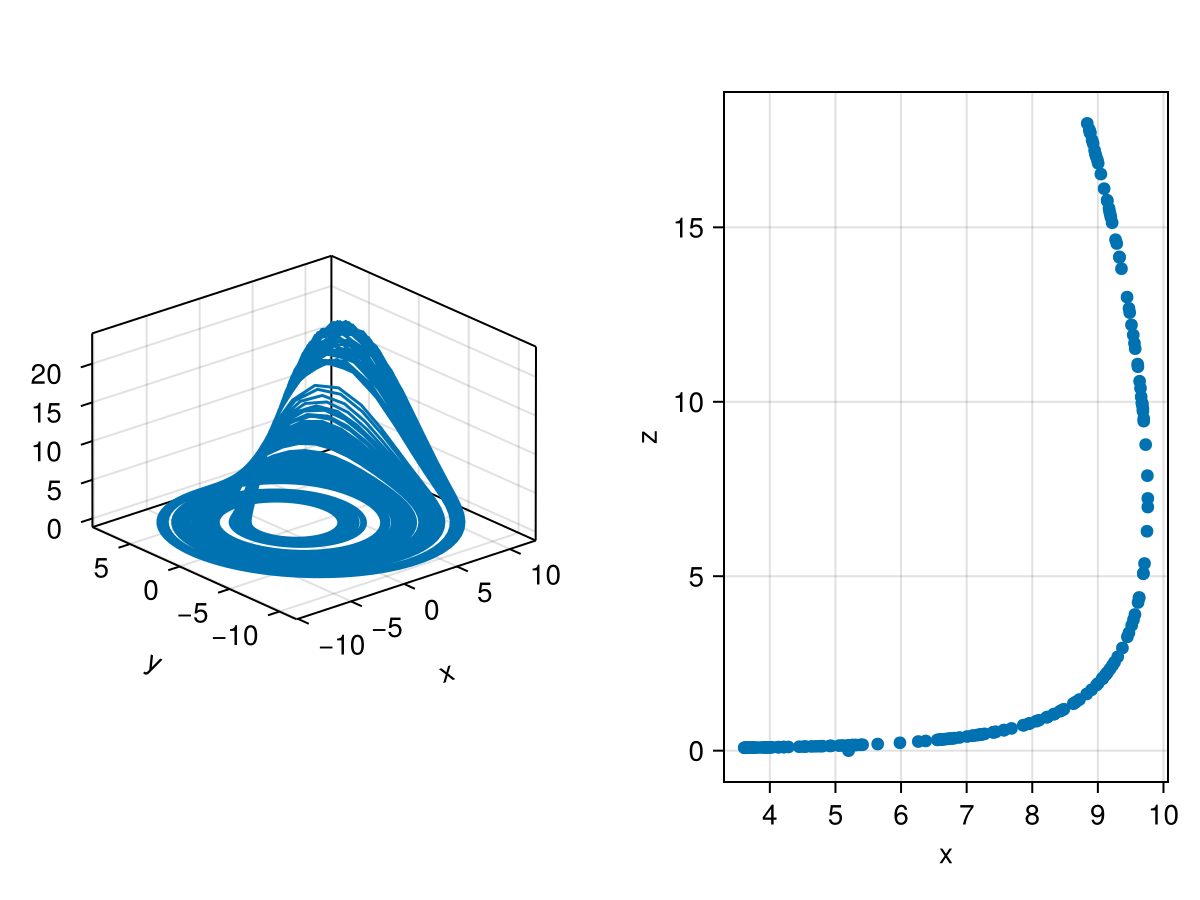

In [81]:
A = CoupledODEs(q1, [5.2, 0, 0], [0.2, 0.2, 5.7])
poincare_map = psos1(A, 2, 0.0)
fig = Figure()
ax = Axis3(fig[1, 1])
X, t = trajectory(A, 1000)
lines!(ax, X)
ax = Axis(fig[1, 2], xlabel = "x", ylabel="z")
scatter!(ax, poincare_map[:, 1], poincare_map[:, 3])
fig

In [ ]:
"""
Function to calculate the crossing times of a trajectory over a hyperplane using the poincare poincare_map

Args:
    A: ODE
    tvec: Vector of times (used as end-point of measurings)
    index: Index of variable to use, ie x = 1, y = 2
    value: Value of fixed variable on hyperplane

Returns:
    Vector(float): Crossing times up to (strictly less than) maximum(tvec)
"""
function psos2(A, tvec, index, value)
    max_time = maximum(tvec)
    times = []
    plane = (index, value)
    pmap = poincaremap(A, plane, max_time, direction = -1)
    while true
        step!(pmap)
        t_cross = current_crossing_time(pmap)
        if t_cross < max_time
            push!(times, t_cross)
        else
            return times
        end
    end
end

psos2 (generic function with 1 method)

In [285]:
A = CoupledODEs(q1, [5.2, 0, 0], [0.2, 0.2, 5.7])
return_times = (psos2(A, t, 2, 0.0))
# step!(p_map)
# current_crossing_time(p_map)

170-element Vector{Any}:
   6.320234269587303
  12.256726627180456
  17.99736255424146
  24.16176465379232
  29.15253169808157
  35.46283153619496
  41.73637651561477
  46.500374555255696
  52.81000513315133
  59.11767304162807
   ⋮
 948.248799880902
 954.5590421097235
 960.8529643482765
 965.7418589838522
 972.0522678545732
 978.3512565892703
 983.3116778204104
 989.622299617443
 995.9066764720271